# 02 · sim_v1: real vs synthetic

**Goal:** is sim_v1 close enough to real UPI behaviour to train RUKO on, and closer than the current `data/sim`?

**What counts as real here** (no public dataset has real UPI transactions):
- **NPCI** published totals for Sep 2026 → amounts and the P2P/P2M mix (India, official)
- **Xente** real mobile-money transactions (Uganda) → *shape only*: time of day and how unequal users are

**Compared:** `sim_v1` (train world, 3,000 users × 60 days) · `data/sim` (current team simulator, 2,000 × 30) · Xente (real).

Every section asks one question, shows one table or chart, and ends with **Inference**.

**Run notebook 01 first** (it writes `data/sim_v1_out/train` and `eval`). This notebook builds the current `data/sim` world itself if it is missing.

In [1]:
import json, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT / 'backend'), str(ROOT / 'ml'), str(ROOT / 'data')]
from eval.datasets.references import xente
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import cross_val_predict, StratifiedKFold
import lightgbm as lgb
pd.set_option('display.precision', 3); plt.rcParams['figure.figsize'] = (9, 3.6)
ANCH = json.loads((ROOT / 'data/eval/realism/npci_anchors.json').read_text())['targets']
SCORE = json.loads((ROOT / 'data/eval/datasets/scorecard.json').read_text())['datasets']

def v1(world):
    d = ROOT / 'data/sim_v1_out' / world
    p, a, u = (pd.read_parquet(d / f'{t}.parquet') for t in ('payments', 'accounts', 'users'))
    p = p[p.user_id.notna()].copy()            # payments made by our users (what RUKO scores)
    return p, a, u

def team():
    d = ROOT / 'data/sim_v1_out/team_sim'   # the current data/sim, default settings (2,000 users x 30 days, seed 7)
    if not (d / 'ledger.parquet').exists():
        from sim.config import SimConfig
        from sim.generate import build_world, write_world
        cfg = SimConfig(); write_world(build_world(cfg), cfg, d)
    L, A, U = (pd.read_parquet(d / f'{t}.parquet') for t in ('ledger', 'accounts', 'users'))
    p = L[L.from_upi.isin(U.upi_id)].copy()
    p['user_id'] = p.from_upi.map(U.set_index('upi_id').user_id)
    merch = set(A.upi_id[A.holder_type == 'merchant'])
    p['kind'] = np.where(p.to_upi.isin(merch), 'P2M', 'P2P')
    return p, A, U

V1, V1A, V1U = v1('train'); TEAM, TA, TU = team()
X = xente().tx; XL = X[X.label == 0]
print(f'sim_v1 user payments {len(V1):,} (scam {int(V1.label_is_scam.sum())}) | data/sim {len(TEAM):,} (scam {int(TEAM.label_is_scam.sum())}) | Xente {len(X):,}')

sim_v1 user payments 296,458 (scam 434) | data/sim 63,958 (scam 77) | Xente 95,662


## 0. Why build our own instead of using a downloaded dataset?
Scorecard from `python -m eval.datasets.score` (7 downloaded sets). `npci` = share of NPCI numbers matched; `labels` = 1.0 when fraud labels are learnable but not trivially easy.

In [2]:
rows = {n: {**s['parts'], 'total': s['total'], 'label verdict': s['labels']['verdict']} for n, s in SCORE.items()}
pd.DataFrame(rows).T.sort_values('total', ascending=False)

,schema,npci,behaviour,labels,transfer,total,label verdict
saml_d,0.6,0.0,0.804,1.0,0.123,0.489,"learnable, not trivial"
paysim,0.6,0.0,0.73,1.0,0.125,0.478,"learnable, not trivial"
ibm_amlworld_hi_small,0.6,0.0,0.206,1.0,0.102,0.396,"learnable, not trivial"
xente_real,0.6,0.0,1.0,0.3,0.137,0.381,too easy (a simple rule gives the label away)
skullagos_upi_2024,0.6,0.0,0.828,0.2,0.11,0.331,no learnable signal (labels look random)
razorpay_upi_sim,0.4,0.0,0.0,1.0,0.104,0.316,"learnable, not trivial"
belbino_banking_upi,0.6,0.0,0.445,0.2,0.106,0.273,no learnable signal (labels look random)


**Inference:** no downloaded dataset matches even one NPCI number (`npci` = 0 everywhere). The two Indian UPI sets (skullagos, belbino) have **random labels**: no column or simple rule beats a coin flip, so nothing can be learned from them. Xente is real but its labels are given away by the amount alone. So the only route is our own generator, tuned to NPCI (amounts) and Xente (behaviour shape).

## 1. Do the amounts and the P2P/P2M mix match NPCI?
Target ± tolerance from `npci_anchors.json`. ✅ = within tolerance.

In [3]:
def anchors(p):
    m, q = p[p.kind == 'P2M'].amount, p[p.kind == 'P2P'].amount
    return {'p2m_share_of_volume': len(m) / (len(m) + len(q)), 'p2m_share_of_value': m.sum() / (m.sum() + q.sum()),
            'avg_ticket_p2p_inr': q.mean(), 'avg_ticket_p2m_inr': m.mean(),
            'p2m_share_below_500': (m < 500).mean(), 'p2p_share_below_500': (q < 500).mean()}
def ok(k, v):
    a = ANCH[k]; e = abs(v - a['value']) / a['value'] if 'tolerance_rel' in a else abs(v - a['value'])
    return '✅' if e <= a.get('tolerance_rel', a.get('tolerance')) else '❌'
sk = {k: v['got'] for k, v in SCORE['skullagos_upi_2024']['npci']['anchors'].items()}
legit = lambda p: p[~p.label_is_scam]
tab = pd.DataFrame({'NPCI (real)': {k: ANCH[k]['value'] for k in ANCH}, 'sim_v1': anchors(legit(V1)),
                    'data/sim': anchors(legit(TEAM)), 'skullagos (Kaggle)': sk})
for c in ['sim_v1', 'data/sim', 'skullagos (Kaggle)']:
    tab[c + ' ok'] = [ok(k, v) for k, v in tab[c].items()]
tab

,NPCI (real),sim_v1,data/sim,skullagos (Kaggle),sim_v1 ok,data/sim ok,skullagos (Kaggle) ok
p2m_share_of_volume,0.633,0.619,0.875,0.438,✅,❌,❌
p2m_share_of_value,0.302,0.273,0.418,0.440,✅,❌,❌
avg_ticket_p2p_inr,2320.000,2461.480,3375.258,1308.681,✅,❌,❌
avg_ticket_p2m_inr,582.000,569.735,345.519,1320.073,✅,❌,❌
p2m_share_below_500,0.860,0.847,0.861,0.424,✅,✅,❌
p2p_share_below_500,0.590,0.595,0.319,0.427,✅,❌,❌


**Inference:** sim_v1 matches **all 6** NPCI numbers (e.g. 84.7% of P2M under ₹500 vs real 86%; P2M share 61.9% vs 63.3%). `data/sim` matches 1 of 6: it sends 87.5% of payments to merchants and its P2P payments are too big (only 32% under ₹500 vs 59%). The Kaggle UPI set matches none. → **Amounts and payment mix are now realistic for India.**

## 2. Do people pay at real times of day?
Share of legit payments per hour. Xente is real; the night (1–5 AM) is where simulators usually go wrong.

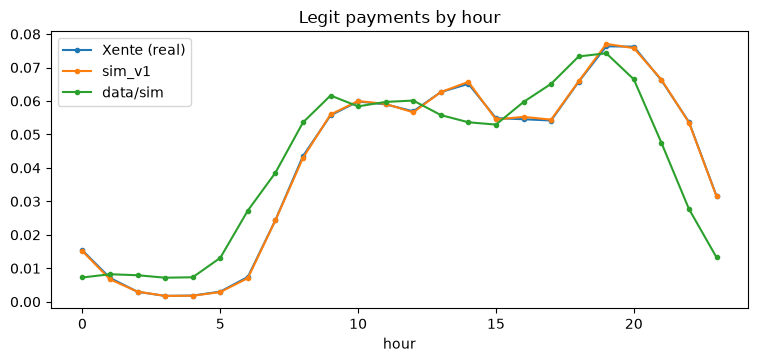

,L1 distance to Xente (0 = same),night share 1-5 AM
Xente (real),0.000,0.017
sim_v1,0.006,0.016
data/sim,0.209,0.044


In [4]:
hp = lambda ts: np.bincount(ts.dt.hour, minlength=24) / len(ts)
H = pd.DataFrame({'Xente (real)': hp(XL.ts), 'sim_v1': hp(legit(V1).ts), 'data/sim': hp(legit(TEAM).ts)})
H.plot(marker='.', title='Legit payments by hour'); plt.xlabel('hour'); plt.show()
pd.DataFrame({'L1 distance to Xente (0 = same)': H.sub(H['Xente (real)'], axis=0).abs().sum(),
              'night share 1-5 AM': H.loc[1:5].sum()})

**Inference:** sim_v1 follows the real hour curve almost exactly (L1 = 0.006) and its night share is 1.6% vs real 1.7%. `data/sim` puts 4.4% of payments at 1–5 AM (2.6× too many). Note: sim_v1 *copies* Xente's curve, so this match is by design. It shows the copy works, not that UPI users keep Uganda's hours. NPCI's own hourly data would be the better target if we can get it.

## 3. Are users as unequal as real users?
Real people differ a lot: some pay twice a month, some ten times a day. We compare the spread of each user's daily rate (log scale), not the level (Xente is a single service, so its users pay less often overall).

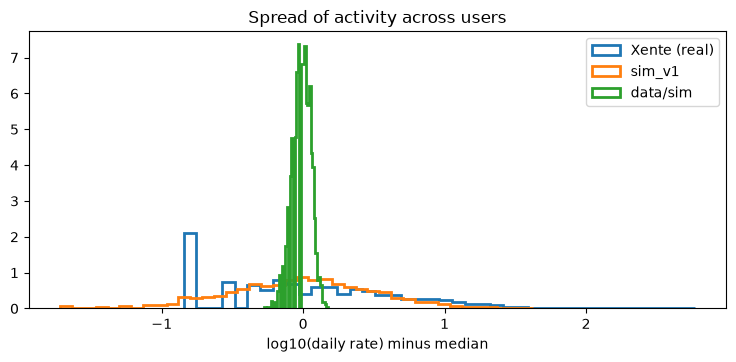

,std of log10 rate,p90 / p10 (x)
Xente (real),0.640,58.000
sim_v1,0.514,20.273
data/sim,0.066,1.462


In [5]:
def rates(p, days):
    return np.log10(p.groupby('user_id' if 'user_id' in p else 'user').size() / days)
R = {'Xente (real)': rates(XL.rename(columns={'user': 'user_id'}), 90), 'sim_v1': rates(legit(V1), 60), 'data/sim': rates(legit(TEAM), 30)}
fig, ax = plt.subplots()
for k, r in R.items():
    ax.hist(r - r.median(), bins=40, histtype='step', density=True, label=k, lw=2)
ax.set_xlabel('log10(daily rate) minus median'); ax.legend(); ax.set_title('Spread of activity across users'); plt.show()
pd.DataFrame({k: {'std of log10 rate': r.std(), 'p90 / p10 (x)': 10 ** (r.quantile(.9) - r.quantile(.1))} for k, r in R.items()}).T

**Inference:** real users are very unequal: the busy 10% pay **58×** more often than the quiet 10%. `data/sim` users are almost identical (1.5×), which is why its per-user features were too easy. sim_v1 reaches **20×**: much closer, but still too narrow. **Fix:** raise `activity_sigma` from 1.1 to about 1.4 (one knob in `config.py`).

## 4. Can a model tell synthetic from real? (C2ST)
Train a classifier to separate synthetic payments from real Xente ones. **AUC 0.5 = indistinguishable (best), 1.0 = obviously fake.**
Only currency-free features: hour of day, the user's activity level relative to the median user, and amount relative to that user's own median (how spiky a user is). Raw amounts are not compared (UGX vs INR, airtime vs UPI).

In [6]:
def c2st_feats(p, days, user_col='user_id'):
    g = p.groupby(user_col)
    r = np.log10(g.amount.transform('size') / days)
    return pd.DataFrame({'hour': p.ts.dt.hour, 'log_user_rate': r - r.median(),  # spread, not level
                         'amount_vs_own_median': np.log1p(p.amount) - np.log1p(g.amount.transform('median'))})
def c2st(a, b, seed=7):
    n = min(len(a), len(b), 60_000)
    Z = pd.concat([a.sample(n, random_state=seed), b.sample(n, random_state=seed)])
    y = np.r_[np.zeros(n), np.ones(n)]
    out = {}
    for cols in (['hour'], ['log_user_rate'], ['amount_vs_own_median'], list(Z.columns)):
        p = cross_val_predict(lgb.LGBMClassifier(n_estimators=150, verbose=-1), Z[cols], y,
                              cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba')[:, 1]
        out[' + '.join(cols) if len(cols) < 3 else 'all three'] = roc_auc_score(y, p)
    return out
FX = c2st_feats(XL, 90, 'user')
C = pd.DataFrame({'sim_v1 vs Xente': c2st(c2st_feats(legit(V1), 60), FX), 'data/sim vs Xente': c2st(c2st_feats(legit(TEAM), 30), FX)})
C

,sim_v1 vs Xente,data/sim vs Xente
hour,0.498,0.581
log_user_rate,0.879,1.000
amount_vs_own_median,0.922,0.934
all three,0.970,1.000


**Inference:**
- **Time of day:** indistinguishable from real (AUC 0.50).
- **User activity:** a model can still tell sim_v1 apart (0.88), and `data/sim` is perfectly separable (1.00).
- **Amount spikiness vs own median:** both differ from Xente (0.92 / 0.93). That's expected: Xente is airtime and bills, not UPI, so this row says little.
- **All three together:** 0.97 vs 1.00. **sim_v1 is closer to real but still recognisably synthetic.** The remaining gap is mostly user activity (see section 3).

## 5. Is the scam label learnable but not given away?
For every single feature RUKO could see, how well does it alone separate scam from legit payments (ROC AUC, out of fold)? **Any feature ≥ 0.95 is a leak:** the model would learn a shortcut that does not exist in real life.

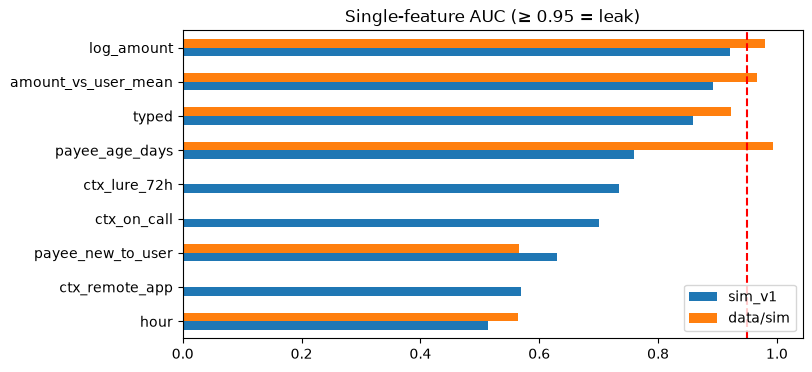

,sim_v1,data/sim
log_amount,0.921,0.980
amount_vs_user_mean,0.893,0.966
typed,0.859,0.923
payee_age_days,0.760,0.994
ctx_lure_72h,0.734,NaN
ctx_on_call,0.701,NaN
payee_new_to_user,0.629,0.566
ctx_remote_app,0.570,NaN
hour,0.514,0.564


In [7]:
def det_feats(p, A):
    p = p.sort_values('ts').copy()
    created = A.set_index('upi_id').created_at
    f = pd.DataFrame(index=p.index)
    f['payee_age_days'] = (p.ts - p.to_upi.map(created)).dt.total_seconds() / 86400
    f['log_amount'] = np.log1p(p.amount)
    la = np.log1p(p.amount); g = la.groupby(p.user_id); n = g.cumcount()
    f['amount_vs_user_mean'] = la - (g.cumsum() - la) / n.replace(0, np.nan)
    f['payee_new_to_user'] = (~p.duplicated(['user_id', 'to_upi'])).astype(float)
    f['typed'] = (p.entry_method == 'typed').astype(float)
    f['hour'] = p.ts.dt.hour
    for c in ('ctx_on_call', 'ctx_remote_app', 'ctx_lure_72h'):
        if c in p: f[c] = p[c].astype('float')
    return f, p.label_is_scam.astype(int).to_numpy()
def single_auc(f, y):
    # rank AUC of the raw value, either direction (0.5 = useless, 1.0 = perfect separation)
    out = {}
    for c in f.columns:
        x = f[c].astype(float)
        if x.notna().sum() < 100 or x.nunique() < 2: continue
        known = x.notna()   # unknown (no consent) is left out, never counted as 'no' (rule 1)
        a = roc_auc_score(y[known], x[known]); out[c] = max(a, 1 - a)
    return pd.Series(out)
FV, yv = det_feats(V1, V1A); FT, yt = det_feats(TEAM, TA)
L = pd.DataFrame({'sim_v1': single_auc(FV, yv), 'data/sim': single_auc(FT, yt)})
ax = L.sort_values('sim_v1').plot.barh(figsize=(8, 4), title='Single-feature AUC (≥ 0.95 = leak)')
ax.axvline(0.95, color='red', ls='--'); plt.show(); L.sort_values('sim_v1', ascending=False)

**Inference:** no sim_v1 feature crosses the 0.95 leak line. `data/sim` has two leaks (payee age 0.994, amount 0.980) and a near-leak (amount vs user 0.966). Payee age falls from 0.994 to **0.76** because honest accounts can be new and mules can be old. Phone signals (call, lure, remote app) each carry real but partial signal (0.57–0.73), which is what CLAUDE.md rule 5 expects: no single family decides. Amount (0.92) is the strongest single clue. That's plausible (scams are larger), but the hard negatives (rent, large first-time payments) should keep it in check.

## 6. Does a model trained on sim_v1 still work on a realistic world?
Train on the **train world** (5% of users scammed), test on the **eval world** (10,000 users, 0.4% scammed, different seed). Budget: alert on 5 of every 1,000 legit payments.

In [8]:
EV, EVA, _ = v1('eval'); FE, ye = det_feats(EV, EVA)
m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, verbose=-1).fit(FV, yv)
pe = m.predict_proba(FE[FV.columns])[:, 1]
thr = np.quantile(pe[ye == 0], 1 - 5 / 1000)
EVs = EV.sort_values('ts').reset_index(drop=True); hit = pe >= thr
caught = EVs.loc[hit & (ye == 1), 'journey_id'].nunique(); total_j = EVs.loc[ye == 1, 'journey_id'].nunique()
res = {'eval scam payments': int(ye.sum()), 'ROC AUC': roc_auc_score(ye, pe), 'PR AUC': average_precision_score(ye, pe),
       'payment recall @5/1000': hit[ye == 1].mean(), 'journeys with ≥1 alert': f'{caught}/{total_j}',
       'precision @5/1000': (ye[hit]).mean()}
imp = pd.Series(m.booster_.feature_importance('gain'), FV.columns); imp = (imp / imp.sum()).sort_values(ascending=False)
display(pd.Series(res)); imp.round(3)

eval scam payments          124
ROC AUC                   0.924
PR AUC                    0.033
payment recall @5/1000    0.516
journeys with ≥1 alert    28/40
precision @5/1000         0.012
dtype: object

payee_age_days         0.283
amount_vs_user_mean    0.167
log_amount             0.143
hour                   0.132
typed                  0.118
ctx_on_call            0.067
ctx_lure_72h           0.055
payee_new_to_user      0.021
ctx_remote_app         0.015
dtype: float64

**Inference:** the problem is now **learnable but hard**, which is what real fraud looks like. Trained on the train world and tested on a separate eval world (10,000 users; 0.012% of payments are scams):
- ROC AUC is 0.92, and PR AUC is 0.033, about 270× better than random.
- At 5 alerts per 1,000 legit payments, the model catches **52%** of scam payments and alerts on **28 of 40** journeys at least once.
- Only 1.2% of alerts are real scams, which is why RUKO needs two independent families before interrupting (rule 5).

Caveat: payee age is still the top feature (28% of gain), because 40% of mules are fresh accounts. Lowering that share is a knob in `config.py` (`mule_kinds`).

## 7. Verdict: what is possible, and how to get closer to real data

**Possible now (shown above):**
- Indian amounts and P2P/P2M mix match NPCI: 6 of 6 checks.
- Time of day matches real behaviour.
- No feature gives the label away.
- A model trained on sim_v1 transfers to a separate, realistic world.
- On every check, sim_v1 beats the current `data/sim` and every downloaded dataset.

**Not possible with public data:** proving that the *scam* part is realistic. No public dataset has real Indian scam payments, so these are still assumptions:
- the playbook mix;
- the ladder shapes and time gaps;
- how often phone signals fire, on scams and on normal payments;
- mule account ages.

The "all three" C2ST of 0.97 also says the joint behaviour is still recognisably synthetic.

**How to get nearer to actual data (in order of value per effort):**
1. **More real aggregates (free, days):**
   - NPCI monthly MCC mix and hourly or peak-hour figures (replace Xente's curve);
   - RBI annual report fraud counts and values by payment type;
   - I4C / NCRP complaint statistics by fraud type and average loss (sets `victim_rate`, playbook weights and loss per journey).
2. **A public case catalogue (1–2 days):** code 40–60 reported cases from news and police advisories into rows: playbook, number of payments, amounts, gaps, call or app used. Fit the ladders and gaps to it instead of guessing.
3. **Discriminator-guided calibration (hours):** add `activity_sigma` and the timing knobs to `calibrate.py`, and minimise the C2ST AUC against Xente together with the NPCI loss.
4. **Aggregated partner data (ask the organisers):** a bank or PSP can usually share *histograms* (amount bands by hour, new-payee rates, scam loss bands) without sharing any rows. Every histogram becomes another calibration target.
5. **Pilot feedback:** once RUKO runs with consenting users, log only aggregate signal rates (rule 2) and re-fit the context base rates.

**Next engineering steps:**
- export sim_v1 in the 7-table format the backend reads;
- raise `activity_sigma`;
- run - re-run this notebook.